# Ảnh hưởng của các tham số EHO

Notebook lần lượt thay đổi các thiết lập của EHO để xem kết quả đổi ra sao. Mỗi cấu hình dùng cùng danh sách **seed**, tức các số giúp lặp lại từng lần chạy. Hình lưu sẵn bên dưới được tạo ở chế độ **FULL** với 25 seed. Chạy lại ở **QUICK** sẽ dùng 5 seed.

**Cách đọc chung.** Fitness là điểm của một nghiệm và ở đây điểm thấp hơn tốt hơn. `mean` là điểm trung bình của các nghiệm tốt nhất mà từng lần chạy tìm được. `std` (SD) cho biết điểm dao động nhiều hay ít giữa các seed. `evaluations` đếm số lần chương trình tính điểm, gồm cả lúc khởi tạo.

In [1]:
from experiment_helpers.artifacts import save_experiment_artifacts

import os
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from eho import EHOConfig
from objectives import rastrigin
from experiment_helpers.runner import (
    assert_reproducible, compare_configurations, results_frame, seeds_for,
)
from experiment_helpers.statistics import summarize_experiment_results

MODE = os.getenv("EHO_EXPERIMENT_MODE", "QUICK").upper()
seeds = seeds_for(MODE)
base = EHOConfig(population_size=20, max_generations=50)
print(MODE, seeds)
print(base)
assert_reproducible(rastrigin, base, seeds[0])
print("Kiểm tra tái lập cùng seed đã đạt.")

FULL [101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125]
EHOConfig(population_size=20, dimension=4, alpha=0.5, beta=0.1, max_generations=50, lower_bounds=(-5.12, -5.12, -5.12, -5.12), upper_bounds=(5.12, 5.12, 5.12, 5.12), random_seed=42)
Kiểm tra tái lập cùng seed đã đạt.


In [2]:
from experiment_helpers.plotting import (
    plot_convergence, plot_fitness_comparison, plot_parameter_heatmap, plot_runtime_comparison,
)

## 1. Alpha

Trong công thức (12.1), với cùng vị trí cũ và cùng số r, alpha lớn hơn làm mỗi tọa độ của cá thể thường tiến xa hơn về phía nghiệm tốt nhất đã tìm thấy. Các thiết lập khác giữ nguyên để ta thấy ảnh hưởng của alpha. Trên biểu đồ đường, mỗi đường theo dõi điểm tốt nhất trung bình qua các thế hệ. Vùng mờ cho biết mức dao động giữa các lần chạy.

,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations
group,,,,,,,,,,,
0.1,25,2.900578e-02,0.101756,0.082806,0.356777,0.075056,5.633456e-03,0.017922,1020.0,1.0,20.00
0.3,25,4.449433e-04,0.005590,0.002804,0.031753,0.006922,4.791577e-05,0.016664,1020.0,1.0,18.36
0.5,25,1.689830e-05,0.000513,0.000359,0.002255,0.000526,2.769456e-07,0.018339,1020.0,1.0,17.52
0.7,25,2.559222e-07,0.000297,0.000059,0.003897,0.000800,6.397936e-07,0.016382,1020.0,1.0,18.36
0.9,25,5.767496e-08,0.000137,0.000006,0.001387,0.000315,9.921882e-08,0.018416,1020.0,1.0,18.48


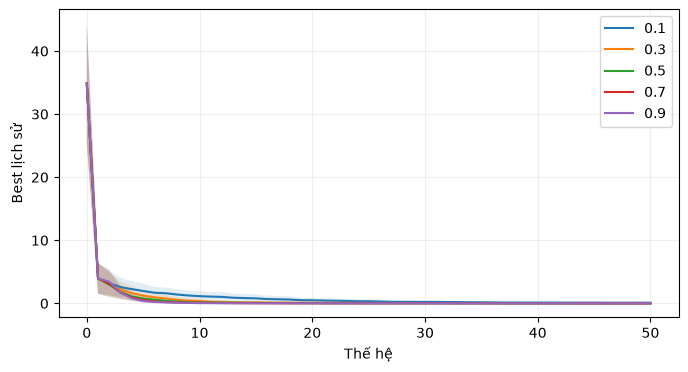

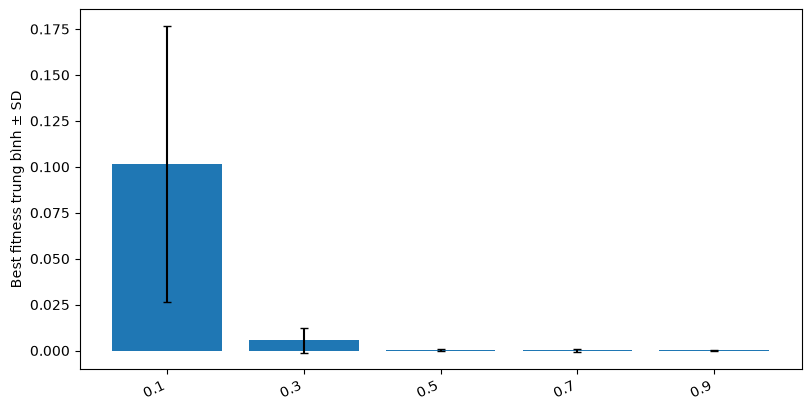

Trong mẫu này, alpha có mean thấp nhất là 0.9. Xem SD để đánh giá độ phân tán.


In [3]:
configs = {value: replace(base, alpha=value) for value in (0.1, 0.3, 0.5, 0.7, 0.9)}
groups = compare_configurations(rastrigin, configs, seeds)
frame = results_frame(groups)
summary = summarize_experiment_results(frame)
display(summary)
plot_convergence(groups)
plot_fitness_comparison(summary)
save_experiment_artifacts("experiment-1-2", "alpha", MODE, seeds, frame, summary)
plt.show()
print(f"Trong mẫu này, alpha có mean thấp nhất là {summary['mean'].idxmin()}. Xem SD để đánh giá độ phân tán.")

## 2. Beta

Công thức (12.2) đặt đầu đàn tại beta nhân với tâm quần thể cũ. Beta bằng 0 làm vị trí mới thành toàn số 0. Trên Rastrigin, điểm gốc có fitness bằng 0, nên kết quả ở beta = 0 dễ giải thích từ công thức. Khi đổi bài toán, điểm gốc có thể là một nghiệm kém.

,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations
group,,,,,,,,,,,
0.0,25,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.016015,1020.0,1.0,17.84
0.1,25,0.000017,0.000513,0.000359,0.002255,0.000526,2.769456e-07,0.015416,1020.0,1.0,17.52
0.3,25,0.000177,0.879390,0.018585,10.899615,2.347649,5.511454e+00,0.015372,1020.0,1.0,15.68
0.5,25,0.014220,5.104442,3.970570,14.576837,4.374686,1.913787e+01,0.015250,1020.0,1.0,16.60
0.8,25,1.016205,5.045311,4.216068,12.978528,3.315474,1.099237e+01,0.015534,1020.0,1.0,17.76


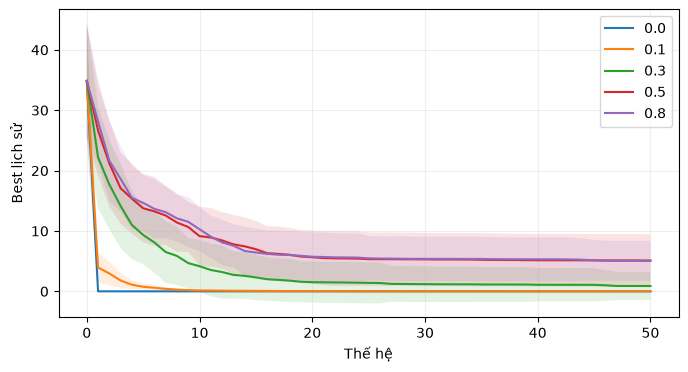

Mean với beta = 0 là 0. Mốc này kiểm tra cơ chế (12.2) trên Rastrigin.


In [4]:
configs = {value: replace(base, beta=value) for value in (0.0, 0.1, 0.3, 0.5, 0.8)}
groups = compare_configurations(rastrigin, configs, seeds)
frame = results_frame(groups)
summary = summarize_experiment_results(frame)
display(summary)
plot_convergence(groups)
save_experiment_artifacts("experiment-1-2", "beta", MODE, seeds, frame, summary)
plt.show()
print(f"Mean với beta = 0 là {summary.loc[0.0, 'mean']:.6g}. Mốc này kiểm tra cơ chế (12.2) trên Rastrigin.")

## 3A. Quần thể ở cùng số thế hệ

Mỗi cấu hình chạy 50 thế hệ. Cấu hình có nhiều cá thể hơn cũng tính fitness nhiều lần hơn trong mỗi thế hệ. Hãy đọc biểu đồ điểm cùng với biểu đồ thời gian để thấy mỗi cấu hình đã dùng bao nhiêu công sức để tìm được điểm đó.

,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations
group,,,,,,,,,,,
5,25,9.001246e-03,0.115185,0.080530,0.418298,0.103422,1.069607e-02,0.005057,255.0,1.0,17.28
10,25,5.681820e-04,0.007194,0.003415,0.029339,0.008022,6.435380e-05,0.008401,510.0,1.0,16.96
20,25,1.689830e-05,0.000513,0.000359,0.002255,0.000526,2.769456e-07,0.015421,1020.0,1.0,17.52
40,25,1.185335e-08,0.000070,0.000027,0.000461,0.000112,1.264591e-08,0.029283,2040.0,1.0,17.16


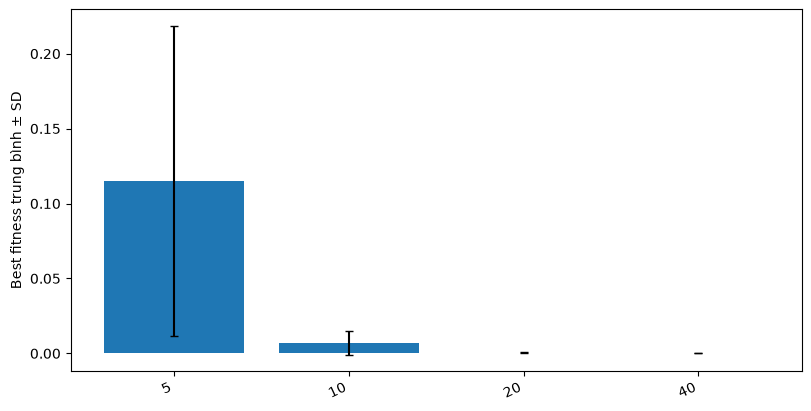

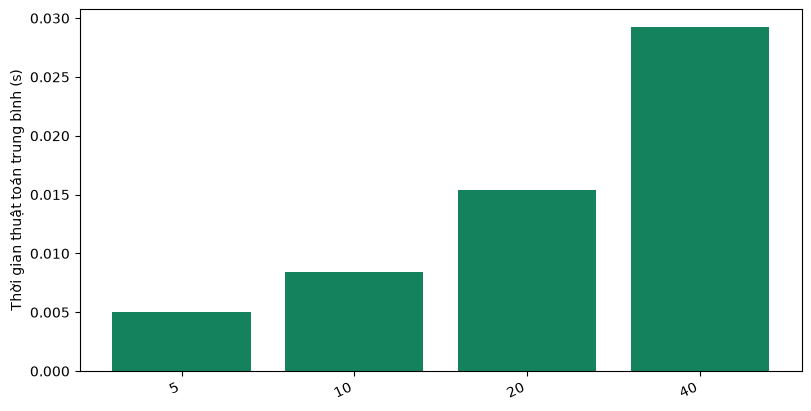

Evaluations tăng từ 255 đến 2040. Cần so thêm ngân sách cố định.


In [5]:
configs = {size: replace(base, population_size=size) for size in (5, 10, 20, 40)}
groups = compare_configurations(rastrigin, configs, seeds)
frame = results_frame(groups)
summary = summarize_experiment_results(frame)
display(summary)
plot_fitness_comparison(summary)
plot_runtime_comparison(summary)
save_experiment_artifacts("experiment-1-2", "population-generations", MODE, seeds, frame, summary)
plt.show()
print(f"Evaluations tăng từ {summary.evaluations.min():g} đến {summary.evaluations.max():g}. Cần so thêm ngân sách cố định.")

## 3B. Quần thể ở cùng ngân sách

Mỗi cấu hình được tính fitness đúng 1.200 lần, kể cả quần thể ban đầu. Ví dụ, 20 cá thể dùng 20 lượt ngay khi khởi tạo và 20 lượt mỗi thế hệ sau đó, nên còn 59 thế hệ. Nhìn trục ngang của biểu đồ đường để so các cấu hình tại cùng số lần tính điểm.

,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations
group,,,,,,,,,,,
5,25,0.000074,0.027968,0.008665,0.130568,0.037473,1.404219e-03,0.023636,1200.0,1.0,84.84
10,25,0.000007,0.001205,0.000473,0.012293,0.002589,6.703924e-06,0.020689,1200.0,1.0,42.80
20,25,0.000007,0.000263,0.000211,0.000701,0.000210,4.397511e-08,0.017842,1200.0,1.0,20.00
40,25,0.000060,0.000554,0.000389,0.001491,0.000464,2.150128e-07,0.017015,1200.0,1.0,9.44


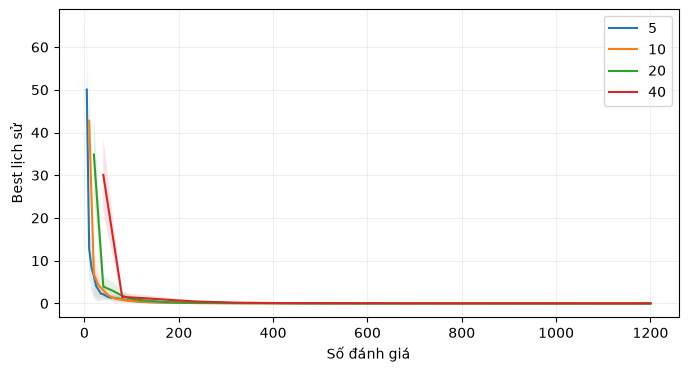

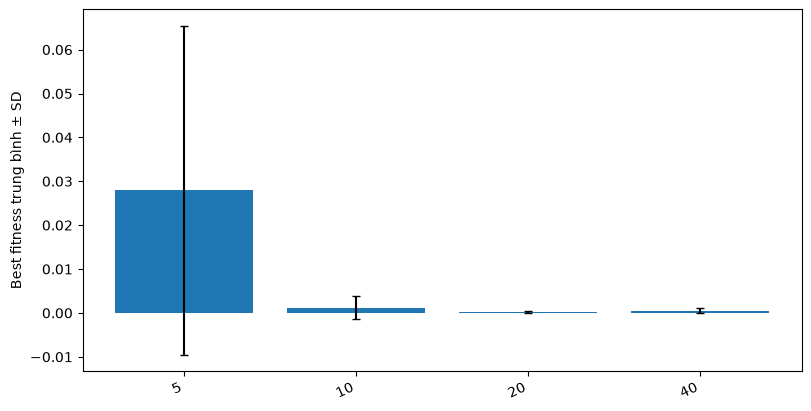

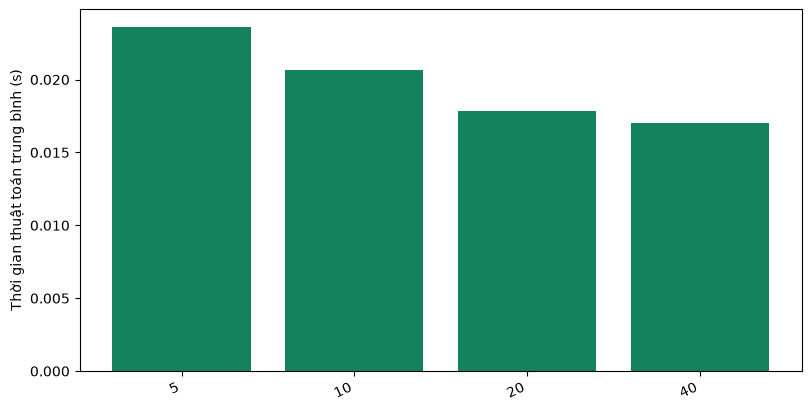

Khi cùng ngân sách, P có mean thấp nhất trong mẫu là 20.


In [6]:
configs = {size: replace(base, population_size=size, max_generations=1200 // size - 1)
           for size in (5, 10, 20, 40)}
groups = compare_configurations(rastrigin, configs, seeds)
frame = results_frame(groups)
summary = summarize_experiment_results(frame)
display(summary)
assert frame.evaluations.eq(1200).all()
plot_convergence(groups, evaluations=True)
plot_fitness_comparison(summary)
plot_runtime_comparison(summary)
save_experiment_artifacts("experiment-1-2", "population-evaluations", MODE, seeds, frame, summary)
plt.show()
print(f"Khi cùng ngân sách, P có mean thấp nhất trong mẫu là {summary['mean'].idxmin()}.")

## 4. Số thế hệ

Thí nghiệm này xem chạy lâu hơn có giúp giảm điểm tốt nhất hay không. Khi một đường nằm ngang, cấu hình tương ứng đã trải qua một số thế hệ mà điểm trung bình của nghiệm tốt nhất chưa giảm thêm. Kết quả chỉ nói về khoảng thời gian đã thử.

,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations
group,,,,,,,,,,,
20,25,4.925700e-03,0.032549,2.856861e-02,0.103129,0.022866,5.228683e-04,0.006104,420.0,1.0,7.04
50,25,1.689830e-05,0.000513,3.590389e-04,0.002255,0.000526,2.769456e-07,0.014701,1020.0,1.0,17.52
100,25,6.878865e-08,0.000041,1.839512e-05,0.000189,0.000050,2.476901e-09,0.030526,2020.0,1.0,35.64
200,25,1.022768e-09,0.000013,1.568226e-07,0.000189,0.000045,2.035131e-09,0.060690,4020.0,1.0,71.76


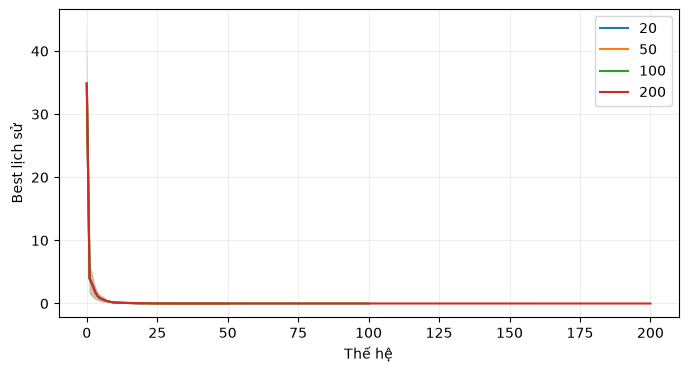

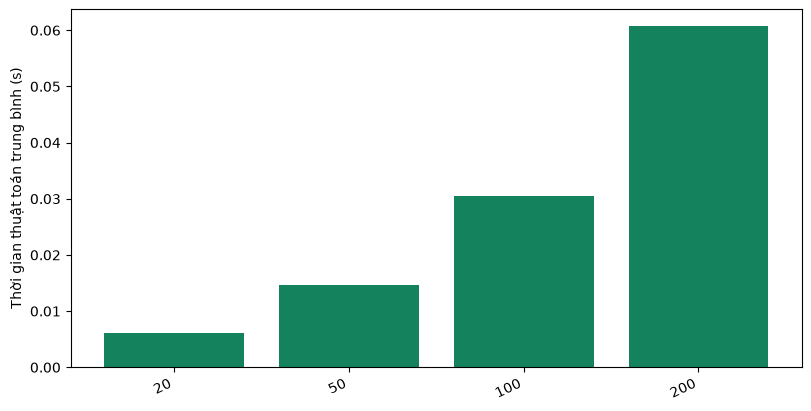

Mean giảm 0.0325359 từ 20 đến 200 thế hệ.


In [7]:
configs = {count: replace(base, max_generations=count) for count in (20, 50, 100, 200)}
groups = compare_configurations(rastrigin, configs, seeds)
frame = results_frame(groups)
summary = summarize_experiment_results(frame)
display(summary)
plot_convergence(groups)
plot_runtime_comparison(summary)
save_experiment_artifacts("experiment-1-2", "generations", MODE, seeds, frame, summary)
plt.show()
print(f"Mean giảm {summary.loc[20, 'mean'] - summary.loc[200, 'mean']:.6g} từ 20 đến 200 thế hệ.")

## 5. Số chiều

Số chiều là số tọa độ phải tìm cho mỗi nghiệm. Rastrigin có thêm một số hạng tính điểm cho mỗi chiều. Vì vậy, đọc cả fitness tổng và fitness chia cho số chiều để hiểu kết quả. Hai cách đọc vẫn dựa trên cùng các lần chạy.

,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations
group,,,,,,,,,,,
2,25,2.892075e-09,0.000002,2.748412e-07,0.000026,0.000005,3.006571e-11,0.015429,1020.0,1.0,9.12
4,25,1.689830e-05,0.000513,3.590389e-04,0.002255,0.000526,2.769456e-07,0.015202,1020.0,1.0,17.52
8,25,2.020276e-03,0.008226,7.055620e-03,0.015881,0.004306,1.854375e-05,0.015027,1020.0,1.0,38.08
12,25,7.649658e-03,0.020112,1.757015e-02,0.047253,0.010477,1.097639e-04,0.015102,1020.0,1.0,52.96


group
2     8.971071e-07
4     1.282548e-04
8     1.028191e-03
12    1.675984e-03
Name: mean, dtype: float64

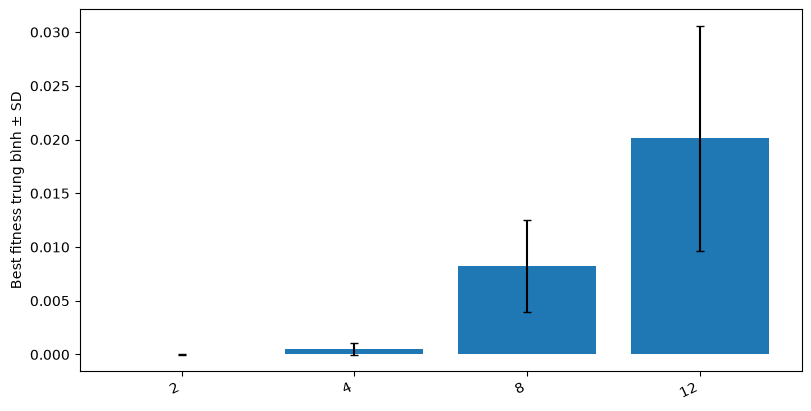

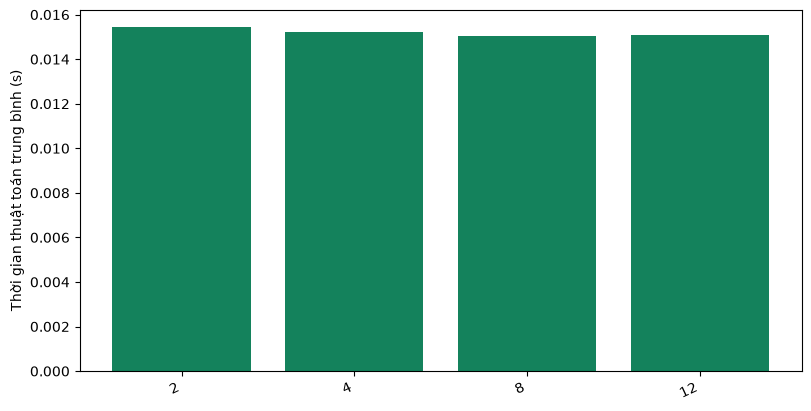

Dimension có độ phân tán mẫu lớn nhất: 12.


In [8]:
configs = {dimension: EHOConfig(dimension=dimension, population_size=20, max_generations=50)
           for dimension in (2, 4, 8, 12)}
groups = compare_configurations(rastrigin, configs, seeds)
frame = results_frame(groups)
summary = summarize_experiment_results(frame)
display(summary)
display(summary["mean"] / summary.index.to_numpy())
plot_fitness_comparison(summary)
plot_runtime_comparison(summary)
save_experiment_artifacts("experiment-1-2", "dimension", MODE, seeds, frame, summary)
plt.show()
print(f"Dimension có độ phân tán mẫu lớn nhất: {summary['std'].idxmax()}.")

## 6. Tương tác Alpha và Beta

Mỗi ô trong bảng màu là điểm trung bình khi dùng cặp alpha và beta tương ứng. Số cá thể là 20, số chiều là 4 và số thế hệ là 50. Đọc theo từng hàng để xem thay alpha ảnh hưởng thế nào khi beta giữ nguyên.

,runs,minimum,mean,median,maximum,std,variance,seconds,evaluations,feasible_rate,violations
group,,,,,,,,,,,
0.3/0.1,25,4.449433e-04,0.005590,0.002804,0.031753,0.006922,4.791577e-05,0.015659,1020.0,1.0,18.36
0.5/0.1,25,1.689830e-05,0.000513,0.000359,0.002255,0.000526,2.769456e-07,0.015353,1020.0,1.0,17.52
0.7/0.1,25,2.559222e-07,0.000297,0.000059,0.003897,0.000800,6.397936e-07,0.015160,1020.0,1.0,18.36
0.3/0.5,25,3.428764e-02,4.954017,4.667004,12.041194,3.934512,1.548038e+01,0.014847,1020.0,1.0,17.08
0.5/0.5,25,1.422025e-02,5.104442,3.970570,14.576837,4.374686,1.913787e+01,0.015140,1020.0,1.0,16.60
0.7/0.5,25,1.125010e-02,5.045978,3.883430,14.154972,3.410462,1.163125e+01,0.016481,1020.0,1.0,17.16


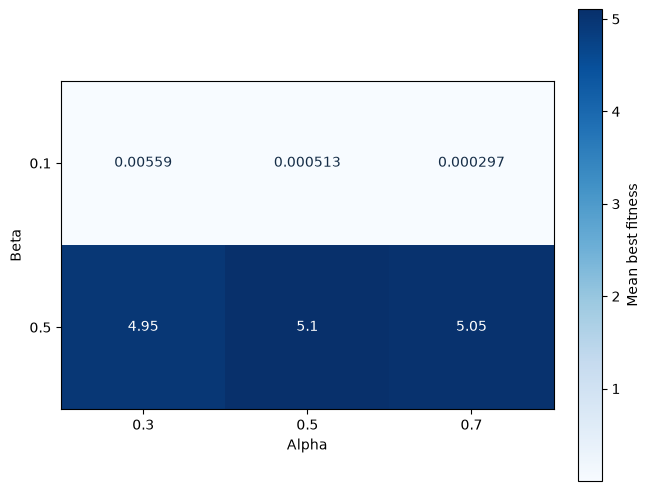

Tổ hợp alpha/beta có mean thấp nhất trong lưới: 0.7/0.1, n=25.


In [9]:
configs = {f"{alpha}/{beta}": replace(base, alpha=alpha, beta=beta)
           for beta in (0.1, 0.5) for alpha in (0.3, 0.5, 0.7)}
groups = compare_configurations(rastrigin, configs, seeds)
frame = results_frame(groups)
summary = summarize_experiment_results(frame)
display(summary)
heatmap = frame.pivot_table(index="beta", columns="alpha", values="fitness", aggfunc="mean")
plot_parameter_heatmap(heatmap)
save_experiment_artifacts("experiment-1-2", "alpha-beta", MODE, seeds, frame, summary)
plt.show()
print(f"Tổ hợp alpha/beta có mean thấp nhất trong lưới: {summary['mean'].idxmin()}, n={len(seeds)}.")

## Kết luận

Hai phép thử số cá thể trả lời hai câu hỏi khác nhau. Giữ 50 thế hệ cho biết chuyện gì xảy ra khi dùng thêm cá thể trong mỗi vòng. Giữ đúng 1.200 lần tính điểm cho biết nên phân bổ cùng một lượng công việc vào nhiều cá thể hay nhiều vòng hơn. Khi dùng kết quả để chọn thiết lập, hãy đối chiếu với số lần tính điểm và các seed đã thử.